<center><h1>Jha_Ria_HW5</h1></center>
<br>
<br>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Decision Trees as Interpretable Models


Import packages


In [1]:
import sys
print(sys.executable)
!{sys.executable} -m pip install xgboost

/usr/local/bin/python3.12

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")

### (a) Obtain Data


Get the Accute Inamations Data Set


In [3]:
ZIP_PATH = "Homework 5 Data.zip"
DATA_DIR = "Homework 5 Data"
with zipfile.ZipFile(ZIP_PATH) as zf:
    members = [m for m in zf.namelist() if not m.startswith("__MACOSX") and m.strip("/")]
    zf.extractall(DATA_DIR, members=members)

diag_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
             "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
diag = pd.read_csv(os.path.join(DATA_DIR, "diagnosis.data"), sep="\t",
                   header=None, names=diag_cols, encoding="utf-16", decimal=",")
for c in diag_cols[1:]:
    diag[c] = (diag[c] == "yes").astype(int)
print(diag.shape)
diag.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree


10    40
01    31
00    30
11    19
Name: count, dtype: int64
Training accuracy: 1.0
Depth: 4 Leaves: 6


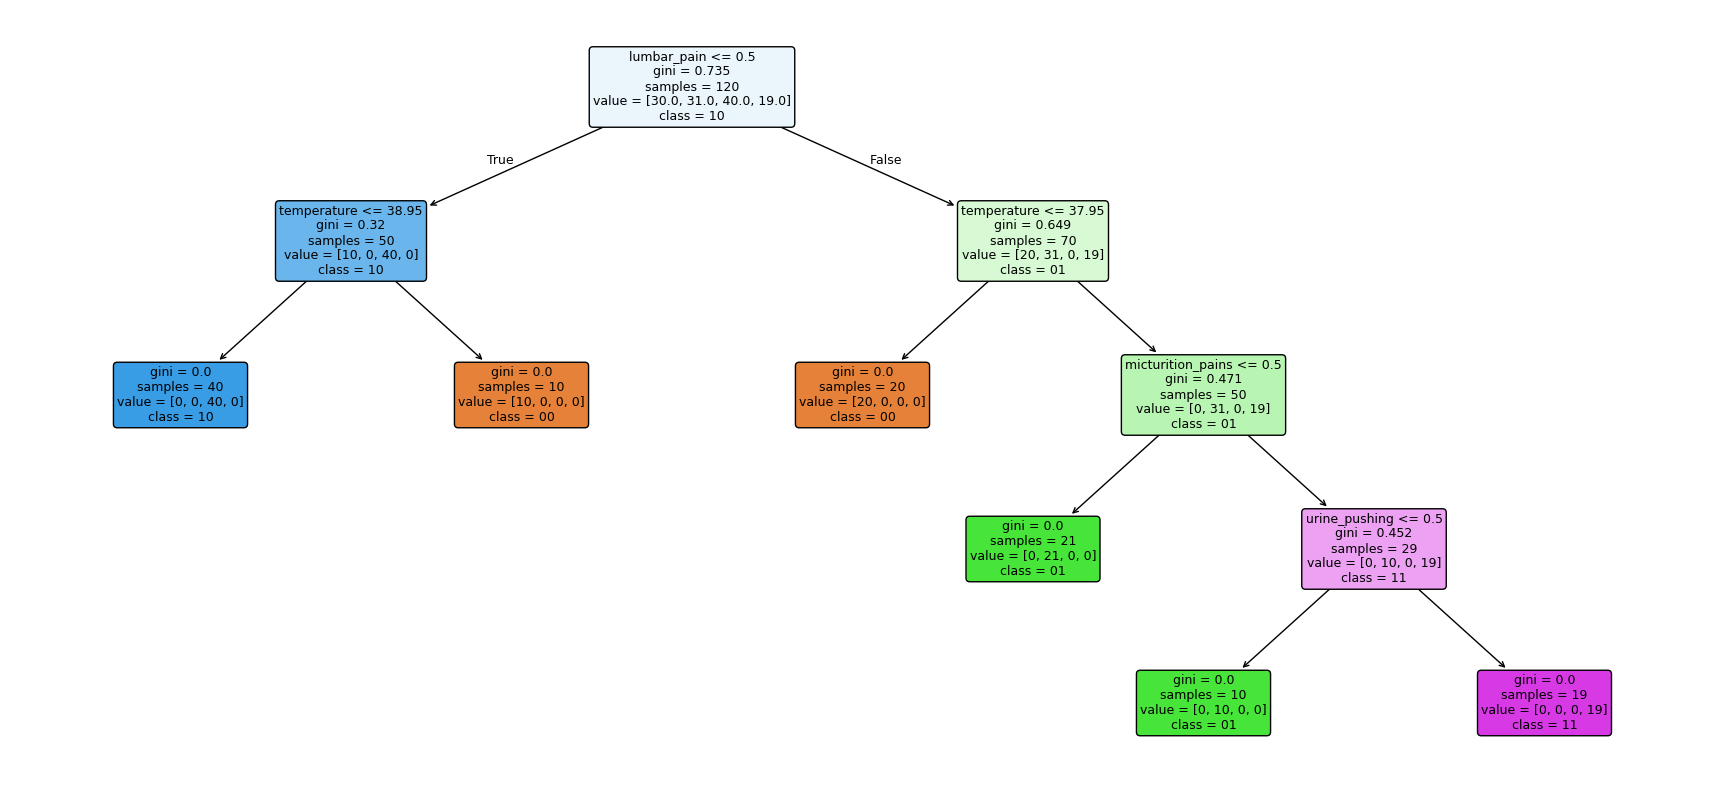

In [4]:
feature_names = diag_cols[:6]
X1 = diag[feature_names]
y_lp = diag["bladder_inflammation"].astype(str) + diag["nephritis"].astype(str)
class_names = sorted(y_lp.unique())
print(y_lp.value_counts())

tree = DecisionTreeClassifier(random_state=0).fit(X1, y_lp)
print("Training accuracy:", tree.score(X1, y_lp))
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=9)
plt.show()

The data has two binary diagnoses (inflammation of the urinary bladder and nephritis of renal pelvis origin), so it is a multi-label problem. I used the label powerset method: the two labels are combined into one 4-class label (first digit = bladder inflammation, second digit = nephritis). The classes are 10 (40 patients), 01 (31), 00 (30) and 11 (19).

A single decision tree fit on all 120 rows with the 6 symptom features has depth 4 and 6 leaves, and reaches 100% training accuracy. The root split is lumbar pain; temperature, micturition pains and urine pushing complete the tree.

### (c) Convert the decision rules


In [5]:
def tree_to_rules(model, feature_names, class_names):
    t = model.tree_
    rules = []
    def recurse(node, conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_names[t.feature[node]]
            thr = t.threshold[node]
            recurse(t.children_left[node], conditions + [f"{name} <= {thr:.2f}"])
            recurse(t.children_right[node], conditions + [f"{name} > {thr:.2f}"])
        else:
            counts = t.value[node][0]
            label = class_names[int(np.argmax(counts))]
            rules.append((conditions, label, int(t.n_node_samples[node])))
    recurse(0, [])
    return rules

def print_rules(rules):
    for i, (conds, label, n) in enumerate(rules, 1):
        print(f"Rule {i}: IF " + " AND ".join(conds) + f" THEN class = {label}  (samples: {n})")

print_rules(tree_to_rules(tree, feature_names, class_names))

Rule 1: IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN class = 10  (samples: 40)
Rule 2: IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN class = 00  (samples: 10)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = 00  (samples: 20)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN class = 01  (samples: 21)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN class = 01  (samples: 10)
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN class = 11  (samples: 19)


The tree gives six mutually exclusive IF-THEN rules that cover every patient:

- No lumbar pain AND temperature <= 38.95 THEN bladder inflammation only (40 patients).
- No lumbar pain AND temperature > 38.95 THEN neither disease (10).
- Lumbar pain AND temperature <= 37.95 THEN neither disease (20).
- Lumbar pain AND temperature > 37.95 AND no micturition pains THEN nephritis only (21).
- Lumbar pain AND temperature > 37.95 AND micturition pains AND no urine pushing THEN nephritis only (10).
- Lumbar pain AND temperature > 37.95 AND micturition pains AND urine pushing THEN both diseases (19).

The rules agree with the data description, which links nephritis to fever and lumbar pain and bladder inflammation to urinary symptoms.

### (d) Cost-complexity pruning

   param_ccp_alpha  mean_test_score  std_test_score
0         0.000000         0.991667        0.016667
1         0.098167         0.858333        0.050000
2         0.133333         0.808333        0.050000
3         0.182000         0.683333        0.067700
4         0.222917         0.483333        0.122474
Best CV accuracy: 0.9917 | chosen ccp_alpha (largest within 1 SE): 0.0


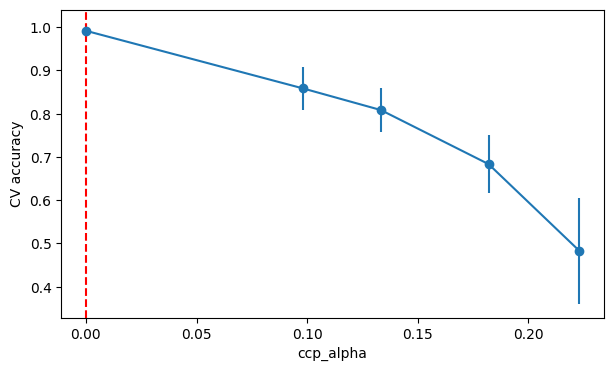

Pruned depth: 4 Leaves: 6 Train accuracy: 1.0


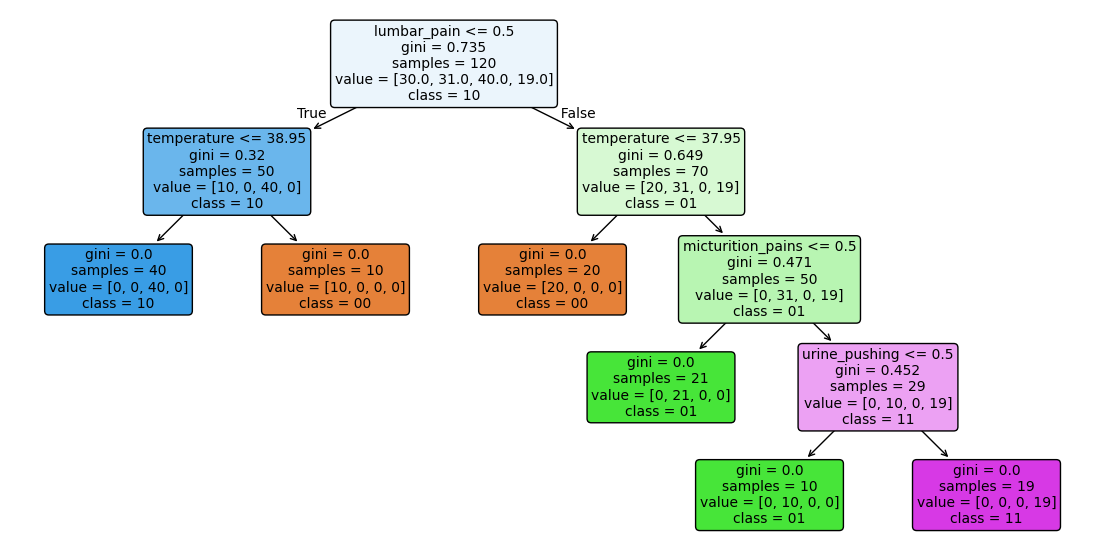

Rule 1: IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN class = 10  (samples: 40)
Rule 2: IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN class = 00  (samples: 10)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = 00  (samples: 20)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN class = 01  (samples: 21)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN class = 01  (samples: 10)
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN class = 11  (samples: 19)


In [6]:
path = tree.cost_complexity_pruning_path(X1, y_lp)
alphas = np.unique(np.round(path.ccp_alphas, 6))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
gs = GridSearchCV(DecisionTreeClassifier(random_state=0), {"ccp_alpha": alphas}, cv=skf)
gs.fit(X1, y_lp)
res = pd.DataFrame(gs.cv_results_)[["param_ccp_alpha", "mean_test_score", "std_test_score"]]
res["param_ccp_alpha"] = res["param_ccp_alpha"].astype(float)
best = res["mean_test_score"].max()
se = res.loc[res["mean_test_score"].idxmax(), "std_test_score"] / np.sqrt(5)
ok = res[res["mean_test_score"] >= best - se]
alpha_star = ok["param_ccp_alpha"].max()
print(res)
print("Best CV accuracy:", round(best, 4), "| chosen ccp_alpha (largest within 1 SE):", alpha_star)

plt.figure(figsize=(7, 4))
plt.errorbar(res["param_ccp_alpha"], res["mean_test_score"], yerr=res["std_test_score"], fmt="o-")
plt.axvline(alpha_star, color="r", ls="--")
plt.xlabel("ccp_alpha"); plt.ylabel("CV accuracy"); plt.show()

pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha_star).fit(X1, y_lp)
print("Pruned depth:", pruned.get_depth(), "Leaves:", pruned.get_n_leaves(), "Train accuracy:", pruned.score(X1, y_lp))
plt.figure(figsize=(14, 7))
plot_tree(pruned, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=10)
plt.show()
print_rules(tree_to_rules(pruned, feature_names, class_names))

I used 5-fold cross-validation over the cost-complexity pruning path and picked the largest ccp_alpha within one standard error of the best score. CV accuracy is 0.992 at ccp_alpha = 0, then falls to 0.858 and 0.808 for the next alphas, and drops further after that. So the best choice is ccp_alpha = 0, and pruning does not simplify the tree: it keeps 6 leaves and the same six rules. Every pruned tree loses accuracy, so the 6-rule tree is already the minimal and most interpretable one for this data. Rules 4 and 5 predict the same class, but the urine pushing split is needed to separate class 11.

## 2. The LASSO and Boosting for Regression


### (a) Obtain Data


In [7]:
attr_names = []
with open(os.path.join(DATA_DIR, "communities.names")) as f:
    for line in f:
        if line.startswith("@attribute"):
            attr_names.append(line.split()[1])
crime = pd.read_csv(os.path.join(DATA_DIR, "communities.data"), header=None,
                    names=attr_names, na_values="?")
train_raw, test_raw = crime.iloc[:1495].copy(), crime.iloc[1495:].copy()
print(crime.shape, train_raw.shape, test_raw.shape)

(1994, 128) (1495, 128) (499, 128)


The data has 1994 communities and 128 columns: 5 non-predictive columns, 122 predictive features and the target ViolentCrimesPerPop. The first 1495 rows are the training set and the remaining 499 are the test set.

### (b) Missing values


In [8]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
feature_cols = [c for c in crime.columns if c not in nonpredictive + [target]]

missing = crime[feature_cols].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(len(missing), "features have missing values")
print(missing.head(8))

imputer = SimpleImputer(strategy="mean")
X_train = pd.DataFrame(imputer.fit_transform(train_raw[feature_cols]), columns=feature_cols)
X_test = pd.DataFrame(imputer.transform(test_raw[feature_cols]), columns=feature_cols)
y_train = train_raw[target].values
y_test = test_raw[target].values
print(X_train.shape, X_test.shape, X_train.isna().sum().sum(), X_test.isna().sum().sum())

23 features have missing values
PctPolicBlack          1675
PctPolicHisp           1675
LemasGangUnitDeploy    1675
LemasPctPolicOnPatr    1675
PolicOperBudg          1675
PolicCars              1675
PolicAveOTWorked       1675
NumKindsDrugsSeiz      1675
dtype: int64
(1495, 122) (499, 122) 0 0


23 features have missing values. 22 of them (all police-related LEMAS features) are missing in 1675 of 1994 rows, and one feature has a single missing value. I dropped the five non-predictive columns (state, county, community, communityname, fold) and used mean imputation, with the mean learned on the training set only and applied to both sets, so no test information leaks in. A limitation: for the LEMAS columns, 84% of the values are filled with a constant, so they carry little real information.

### (c) Plot a correlation matrix


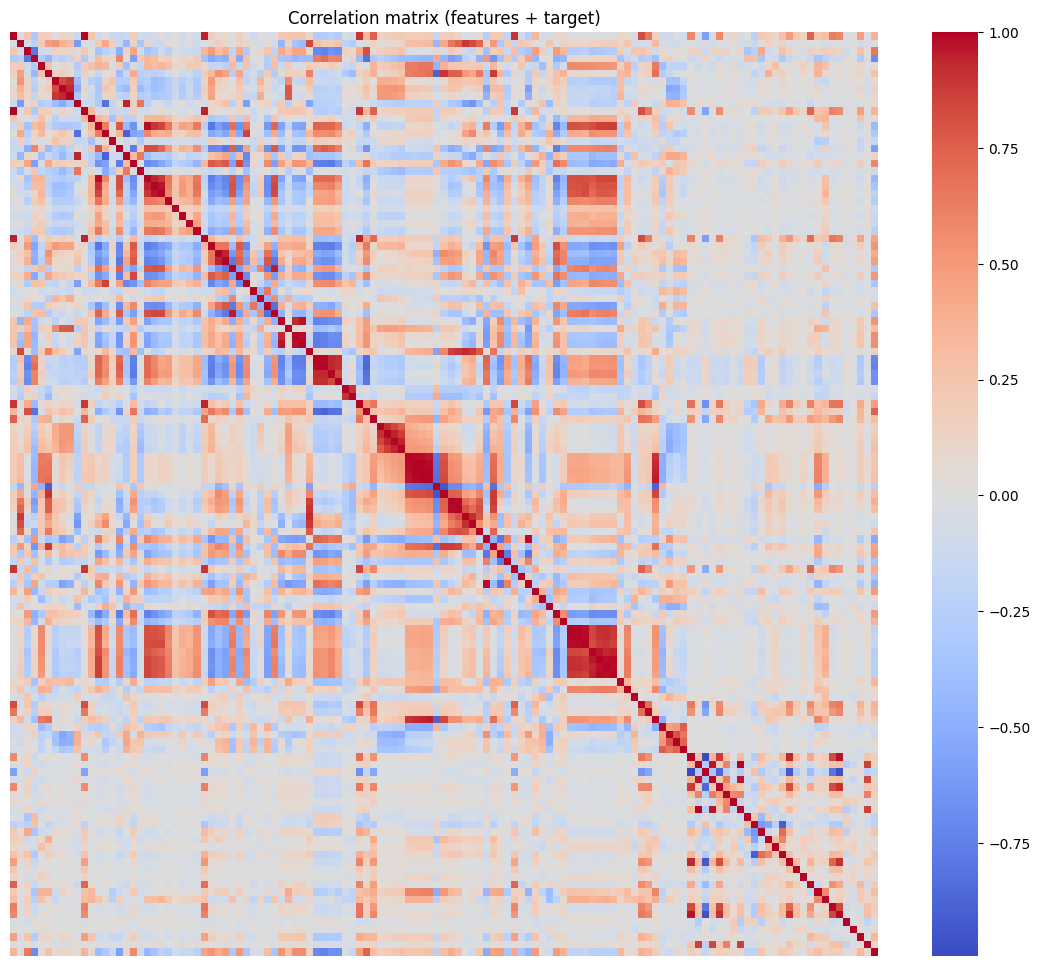

In [9]:
corr = pd.concat([X_train, pd.Series(y_train, name=target)], axis=1).corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix (features + target)")
plt.show()

The matrix shows many strongly correlated groups. 61 feature pairs have |r| > 0.9, for example the race, family-structure and income variables. The features most correlated with the target are PctIlleg (0.74), PctKids2Par (-0.74), PctFam2Par (-0.71), racePctWhite (-0.69) and racepctblack (0.64). Because of this multicollinearity, ordinary least squares is unstable and regularization is expected to help.

### (d) Calculate the Coefficient of Variation CV


In [10]:
cv = (X_train.std(ddof=1) / X_train.mean()).abs().sort_values(ascending=False)
print(cv.head(15))

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
LandArea               1.645408
racePctHisp            1.612091
PctNotSpeakEnglWell    1.456618
racepctblack           1.428885
PctUsePubTrans         1.397110
racePctAsian           1.359100
dtype: float64


CV is the sample standard deviation divided by the mean, computed on the training set. The highest are NumStreet (4.29), NumInShelters (3.47), NumIlleg (3.06), NumImmig (2.93) and LemasPctOfficDrugUn (2.55). Large CV here comes from features that are zero for most communities and large for a few.

### (e) Scatter plots and box plots for highest CV features


11 ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


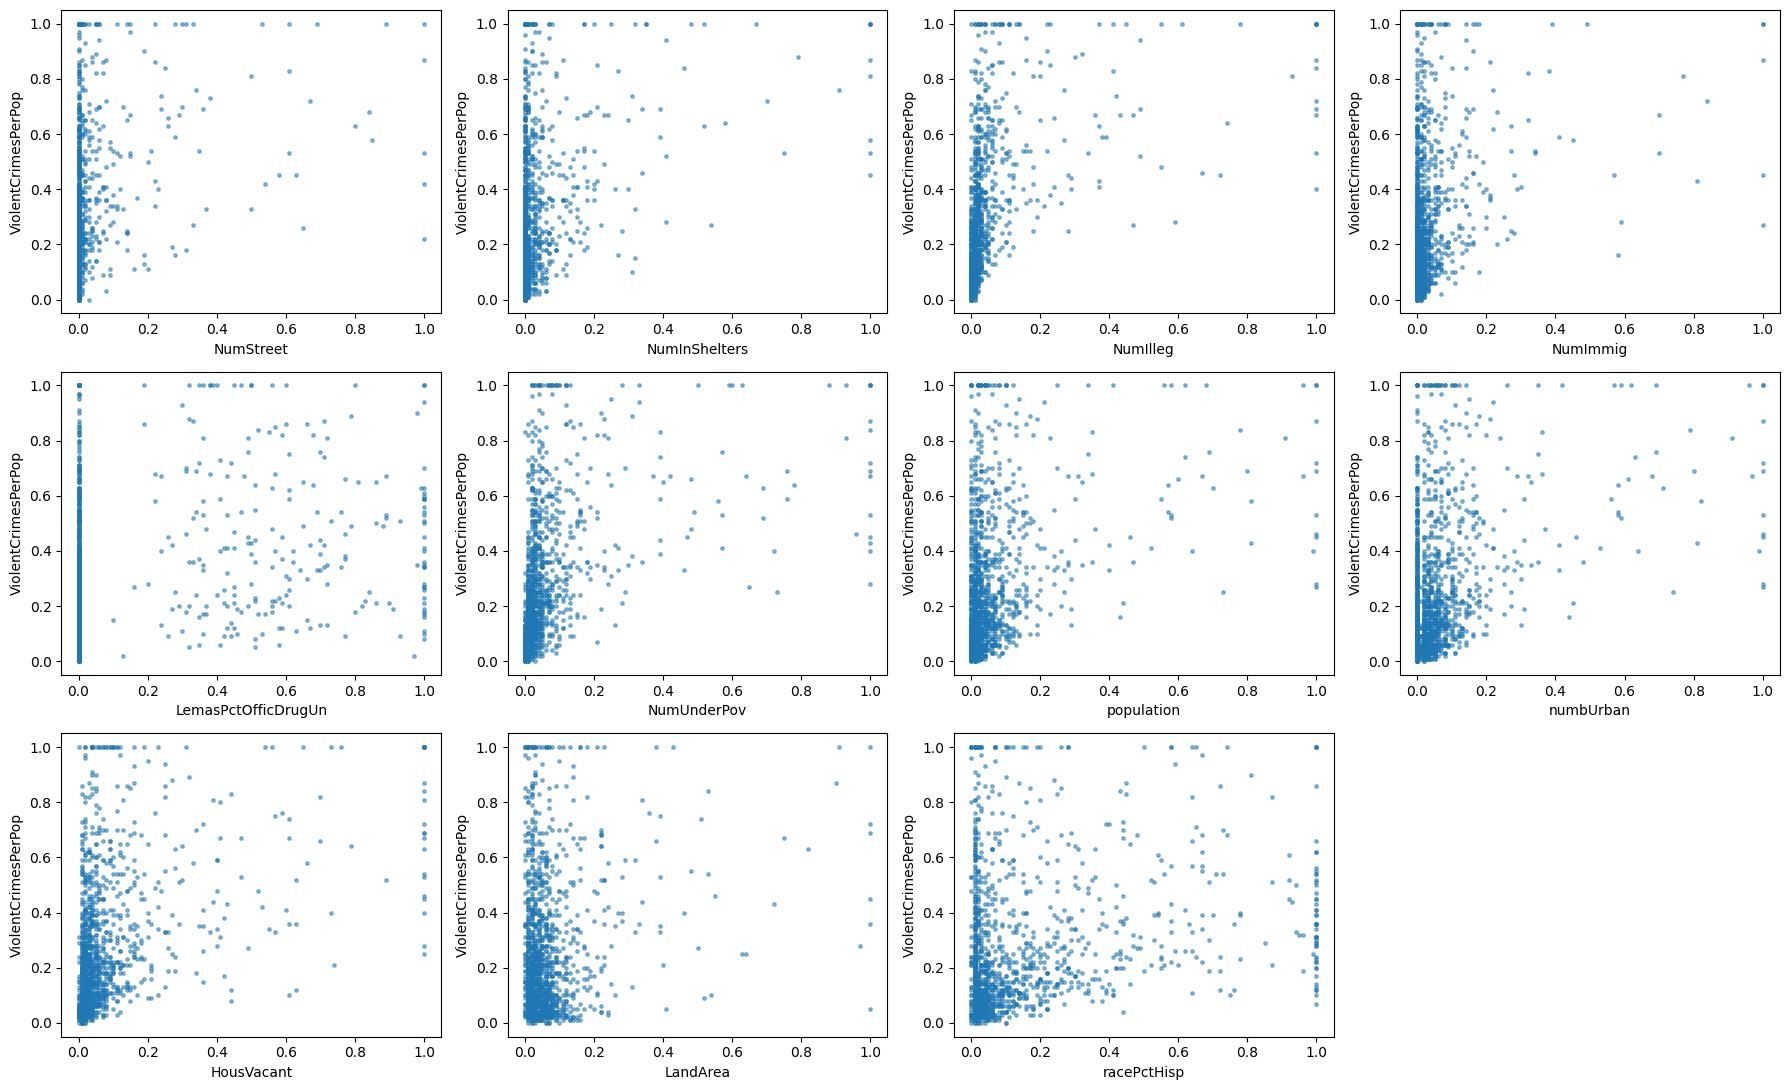

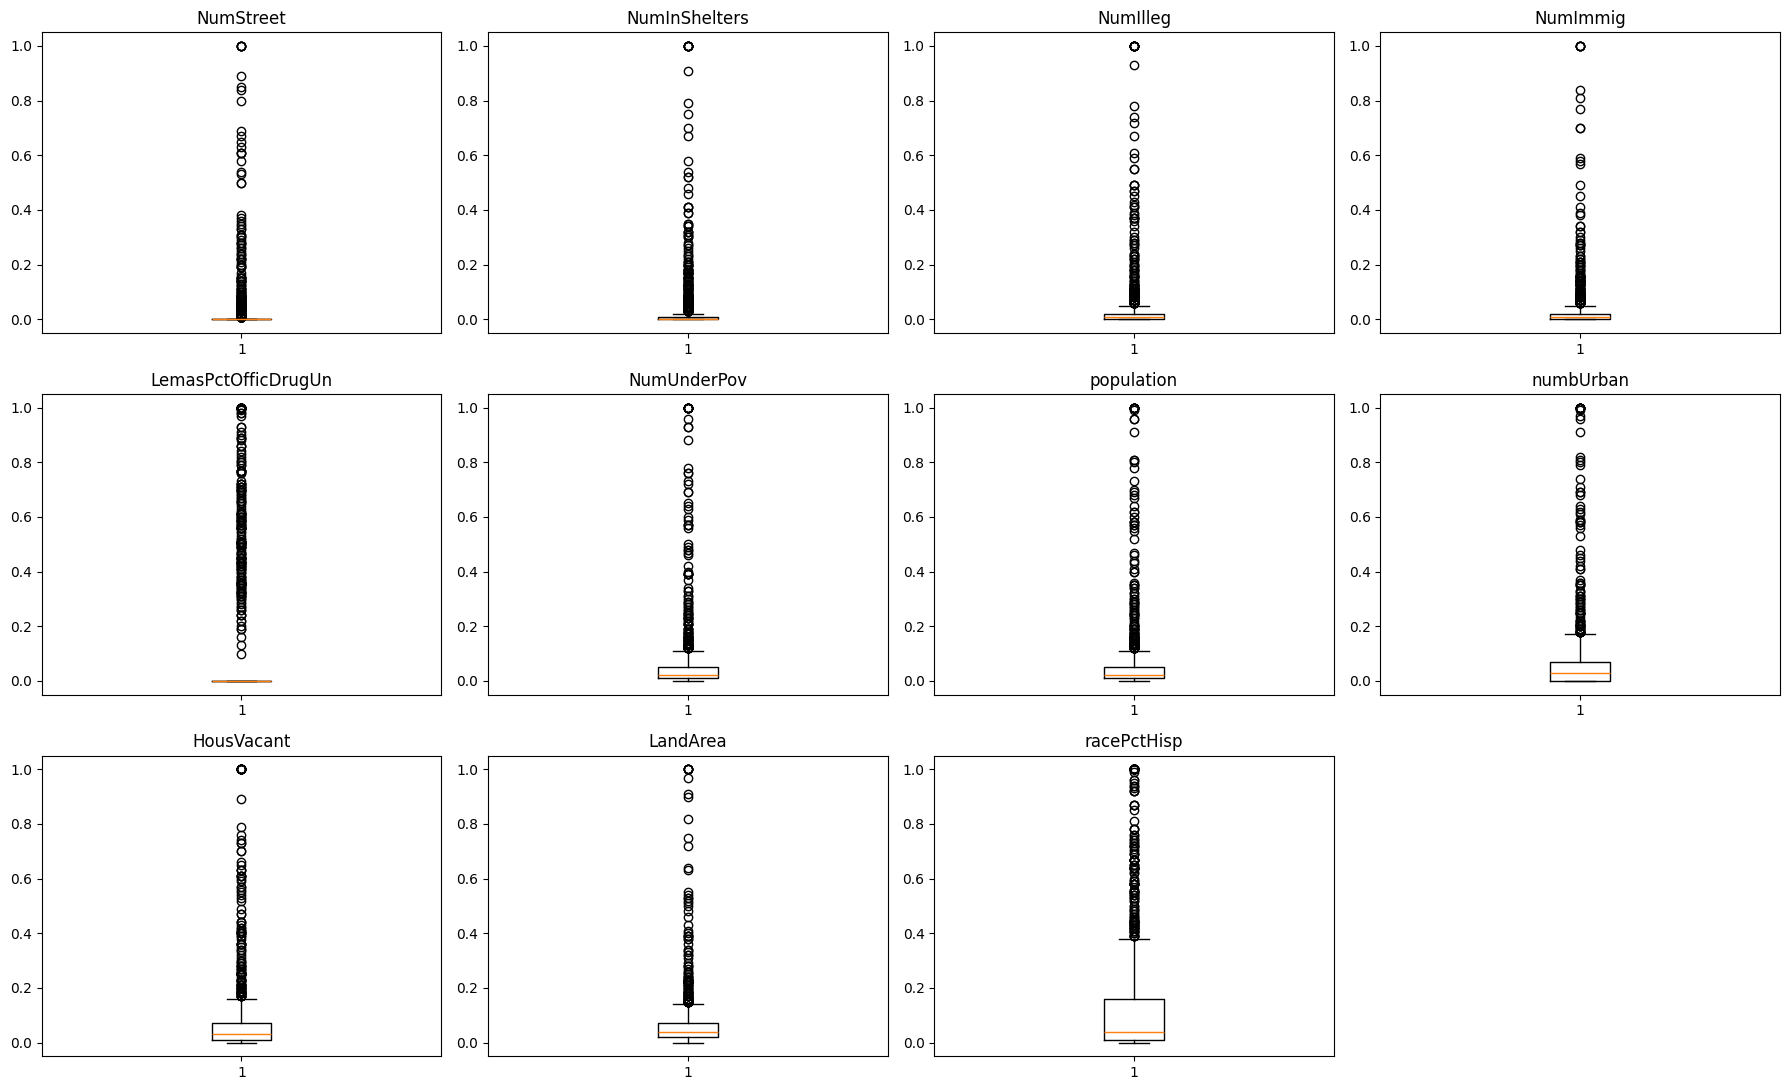

NumStreet              0.332
NumInShelters          0.373
NumIlleg               0.463
NumImmig               0.295
LemasPctOfficDrugUn    0.332
NumUnderPov            0.442
population             0.364
numbUrban              0.362
HousVacant             0.422
LandArea               0.205
racePctHisp            0.289
dtype: float64


In [11]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv.index[:k].tolist()
print(k, top_cv)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), top_cv):
    ax.scatter(X_train[c], y_train, s=6, alpha=0.5)
    ax.set_xlabel(c); ax.set_ylabel(target)
for ax in axes.ravel()[len(top_cv):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), top_cv):
    ax.boxplot(X_train[c], vert=True)
    ax.set_title(c)
for ax in axes.ravel()[len(top_cv):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

print(pd.Series({c: np.corrcoef(X_train[c], y_train)[0, 1] for c in top_cv}).round(3))

The 11 features with the highest CV are NumStreet, NumInShelters, NumIlleg, NumImmig, LemasPctOfficDrugUn, NumUnderPov, population, numbUrban, HousVacant, LandArea and racePctHisp. The box plots show heavy right skew and many outliers: the medians are near 0 and the whiskers are short. The scatter plots show weak positive trends, with correlations with the target between 0.21 and 0.46. I cannot draw conclusions about significance from the scatter plots alone, because the points are concentrated near zero and overlap heavily, and a plot cannot give a p-value. Also, high CV does not mean predictive: the strongest predictors by correlation (PctIlleg, PctKids2Par) are not among them.

### (f) Fit a linear model


In [12]:
ols = LinearRegression().fit(X_train, y_train)
ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print("OLS test MSE:", round(ols_mse, 5))

OLS test MSE: 0.01814


The least squares model has a test MSE of 0.01814.

### (g) Fit a ridge regression model


In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=kf).fit(X_train, y_train)
ridge_mse = mean_squared_error(y_test, ridge.predict(X_test))
print("Ridge lambda:", round(ridge.alpha_, 4), "| test MSE:", round(ridge_mse, 5))

Ridge lambda: 2.0236 | test MSE: 0.01762


Ridge with lambda chosen by 5-fold CV (lambda = 2.02) has a test MSE of 0.01762, better than OLS because shrinkage reduces variance caused by correlated features.

### (h) Fit a LASSO model


In [14]:
lasso = LassoCV(cv=kf, max_iter=50000, random_state=0).fit(X_train, y_train)
lasso_mse = mean_squared_error(y_test, lasso.predict(X_test))
sel = X_train.columns[lasso.coef_ != 0].tolist()
print("LASSO lambda:", round(lasso.alpha_, 6), "| test MSE:", round(lasso_mse, 5), "| selected:", len(sel))
print(sel)

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
lasso_s = LassoCV(cv=kf, max_iter=50000, random_state=0).fit(Xs_train, y_train)
lasso_s_mse = mean_squared_error(y_test, lasso_s.predict(Xs_test))
sel_s = X_train.columns[lasso_s.coef_ != 0].tolist()
print("Standardized LASSO lambda:", round(lasso_s.alpha_, 6), "| test MSE:", round(lasso_s_mse, 5), "| selected:", len(sel_s))
print(sel_s)
print("Only in raw:", sorted(set(sel) - set(sel_s)))
print("Only in standardized:", sorted(set(sel_s) - set(sel)))

LASSO lambda: 8.2e-05 | test MSE: 0.01782 | selected: 80
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'Me

LASSO with lambda chosen by 5-fold CV (lambda = 8.2e-05) selects 80 of the 122 features and has a test MSE of 0.01782. The selected variables are listed in the output above. After standardizing, lambda = 0.000664, 76 features are selected and the test MSE is 0.01784. The errors are nearly identical because the features are already normalized to [0, 1], so standardizing changes little. The selected sets differ slightly: PctBSorMore, PctWorkMomYoungKids, PersPerOwnOccHous, agePct65up and medFamInc are selected only without standardization, and population only with it. Both LASSO models beat OLS but not ridge.

### (i) Fit a PCR model


PCR best M: 96 | test MSE: 0.01847


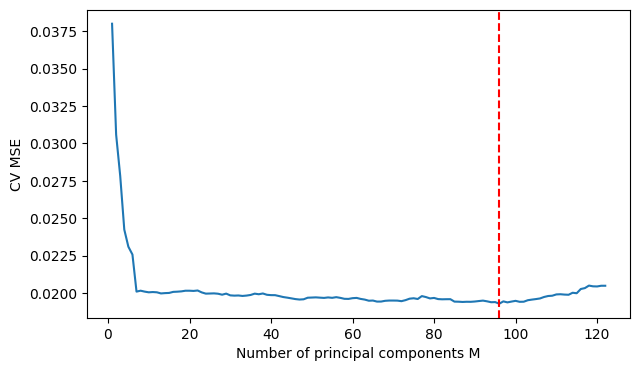

In [15]:
pcr = make_pipeline(PCA(), LinearRegression())
grid = GridSearchCV(pcr, {"pca__n_components": list(range(1, X_train.shape[1] + 1))},
                    cv=kf, scoring="neg_mean_squared_error")
grid.fit(X_train, y_train)
M = grid.best_params_["pca__n_components"]
pcr_mse = mean_squared_error(y_test, grid.predict(X_test))
print("PCR best M:", M, "| test MSE:", round(pcr_mse, 5))

plt.figure(figsize=(7, 4))
plt.plot(range(1, X_train.shape[1] + 1), -grid.cv_results_["mean_test_score"])
plt.axvline(M, color="r", ls="--")
plt.xlabel("Number of principal components M"); plt.ylabel("CV MSE"); plt.show()

Cross-validation selects M = 96 of the 122 principal components, with a test MSE of 0.01847. This is the highest error of all the models. Choosing so many components means PCR gives almost no dimension reduction here, and the components are built without using the target, so they are not necessarily the most predictive directions.

### (j) Fit a boosting tree


In [16]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, reg_lambda=0, random_state=0, n_jobs=-1)
xgb_grid = GridSearchCV(xgb, {"reg_alpha": [0, 0.01, 0.1, 0.5, 1, 2, 5, 10]},
                        cv=kf, scoring="neg_mean_squared_error")
xgb_grid.fit(X_train, y_train)
xgb_mse = mean_squared_error(y_test, xgb_grid.predict(X_test))
print("Best alpha (reg_alpha):", xgb_grid.best_params_["reg_alpha"], "| test MSE:", round(xgb_mse, 5))

results = pd.DataFrame({"Model": ["OLS", "Ridge", "LASSO", "LASSO (standardized)", "PCR", "L1 boosting tree"],
                        "Test MSE": [ols_mse, ridge_mse, lasso_mse, lasso_s_mse, pcr_mse, xgb_mse]})
print(results.round(5).to_string(index=False))

Best alpha (reg_alpha): 0.5 | test MSE: 0.01643
               Model  Test MSE
                 OLS   0.01814
               Ridge   0.01762
               LASSO   0.01782
LASSO (standardized)   0.01784
                 PCR   0.01847
    L1 boosting tree   0.01643


An L1-penalized gradient boosting tree (XGBoost, reg_alpha chosen by 5-fold CV) selects alpha = 0.5 and has a test MSE of 0.01643. The comparison table shows it has the lowest test error of all six models, ahead of ridge (0.01762), LASSO (0.01782 and 0.01784), OLS (0.01814) and PCR (0.01847). Boosting can capture nonlinear effects and interactions that the linear models cannot.